In [3]:
from google.colab import files
uploaded = files.upload()

Saving calendar.zip to calendar.zip


In [2]:
from google.colab import files
uploaded = files.upload()

Saving listings.zip to listings.zip


In [4]:
import pandas as pd
import matplotlib.pyplot as plt

df_l = pd.read_csv('listings.zip')
df_c = pd.read_csv('calendar.zip')

print("df_l (listings):", df_l.shape)
print("df_c (calendar):", df_c.shape)

df_l (listings): (3818, 92)
df_c (calendar): (1393570, 4)


In [5]:
df_l['price'] = (
    df_l['price']
    .astype(str)
    .str.replace('$', '', regex=False)
    .str.replace(',', '', regex=False)
    .astype(float)
)

df_c['price'] = ( df_c['price'].astype(str)
    .str.replace('$', '', regex=False)
    .str.replace(',', '', regex=False)
    .astype(float)
)

df_c['date'] = pd.to_datetime(df_c['date'])
df_c['isbooked']= (df_c['available']=='f').astype(int)

In [6]:
date_df = pd.DataFrame({'date': pd.date_range(start=df_c['date'].min(), end=df_c['date'].max())})
date_df['year'] = date_df['date'].dt.year
date_df['month_num'] = date_df['date'].dt.month
date_df['month_name'] = date_df['date'].dt.month_name()
date_df['quarter'] = date_df['date'].dt.quarter

print("size:", date_df.shape)
print(date_df.head(2))

size: (365, 5)
        date  year  month_num month_name  quarter
0 2016-01-04  2016          1    January        1
1 2016-01-05  2016          1    January        1


In [7]:
# median price according to the neighbourhoods

neighbourhood_median = (
    df_l.groupby("neighbourhood_cleansed")["price"].median().reset_index()
)

neighbourhood_median.columns = ["neighbourhood", "median_price"]

print("median prices:")
print(neighbourhood_median.head())

median prices:
   neighbourhood  median_price
0          Adams          99.5
1           Alki         126.5
2  Arbor Heights         100.0
3       Atlantic          95.0
4       Belltown         139.0


In [8]:
# merging process

merged_df = df_c.merge(
    df_l, left_on="listing_id", right_on="id")

merged_df_neighbourhood = df_l.merge(
    neighbourhood_median,
    left_on="neighbourhood_cleansed",
    right_on="neighbourhood",
)


In [23]:
# brenchmarking

df_l['median_price'] = df_l.groupby('neighbourhood_cleansed')[
    'price'
].transform('median')

df_l['is_above_median'] = df_l['price'] > df_l['median_price']

print(
    df_l[
        [
            'name',
            'neighbourhood_cleansed',
            'price',
            'median_price',
            'is_above_median',
        ]
    ].head(3)
)

                                  name neighbourhood_cleansed  price  \
0         Stylish Queen Anne Apartment        West Queen Anne   85.0   
1   Bright & Airy Queen Anne Apartment        West Queen Anne  150.0   
2  New Modern House-Amazing water view        West Queen Anne  975.0   

   median_price  is_above_median  
0         130.0            False  
1         130.0             True  
2         130.0             True  


In [17]:
# monthly trend

final_analysis_df = merged_df.merge(date_df, on="date")

final_analysis_df["month"] = final_analysis_df["date"].dt.month

monthly_trend = (
    final_analysis_df.groupby("month")[["price_x", "isbooked"]]
    .mean()
    .reset_index()
)

print("results over months:")
print(monthly_trend)


results over months:
    month     price_x  isbooked
0       1  122.912176  0.433063
1       2  124.293927  0.337792
2       3  128.644488  0.290813
3       4  135.097005  0.336153
4       5  139.538183  0.324330
5       6  147.473137  0.325616
6       7  152.094150  0.372903
7       8  150.656594  0.354949
8       9  143.255949  0.325598
9      10  137.031939  0.303486
10     11  135.688738  0.286014
11     12  137.251835  0.264427


In [ ]:
print(final_analysis_df)

         listing_id       date available  price_x  isbooked        id  \
0            241032 2016-01-04         t     85.0         0    241032   
1            241032 2016-01-05         t     85.0         0    241032   
2            241032 2016-01-06         f      NaN         1    241032   
3            241032 2016-01-07         f      NaN         1    241032   
4            241032 2016-01-08         f      NaN         1    241032   
...             ...        ...       ...      ...       ...       ...   
1393565    10208623 2016-12-29         f      NaN         1  10208623   
1393566    10208623 2016-12-30         f      NaN         1  10208623   
1393567    10208623 2016-12-31         f      NaN         1  10208623   
1393568    10208623 2017-01-01         f      NaN         1  10208623   
1393569    10208623 2017-01-02         f      NaN         1  10208623   

                                   listing_url       scrape_id last_scraped  \
0          https://www.airbnb.com/rooms/2410

/tmp/ipykernel_525/3786671654.py:18: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title="Neighbourhood", bbox_to_anchor=(1.05, 1), loc="upper left")


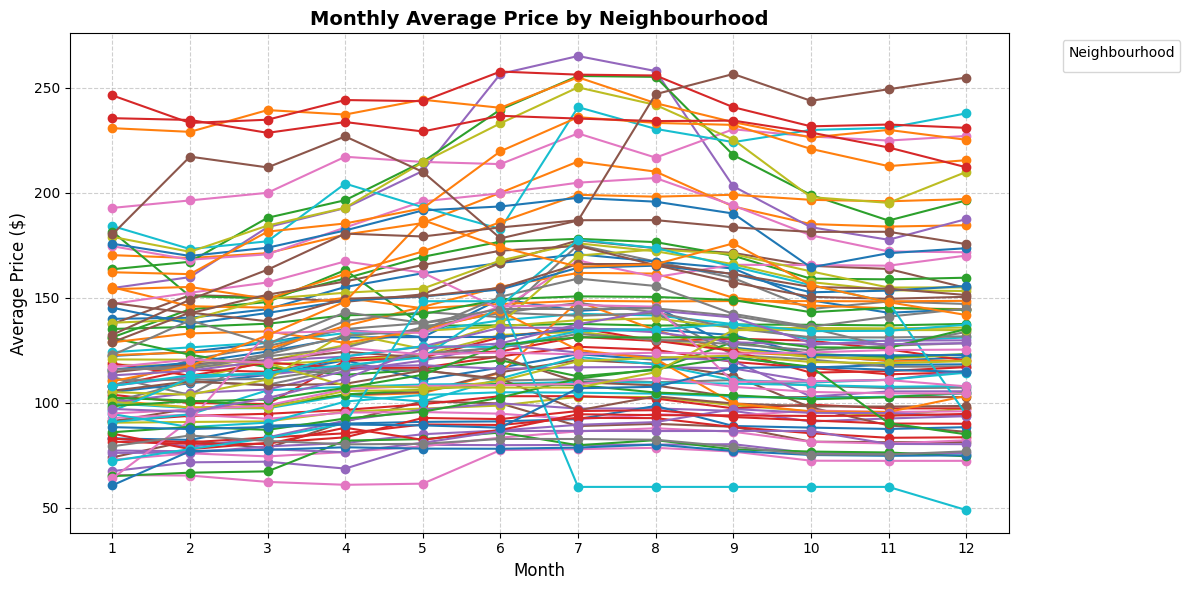

In [ ]:
# monthly average price by neighbourhood

neighbourhood_monthly = final_analysis_df.groupby(["neighbourhood_cleansed", "month"])["price_x"].mean().reset_index()
pivot_df = neighbourhood_monthly.pivot(
    index="month", columns="neighbourhood_cleansed", values="price_x"
)

plt.figure(figsize=(12, 6))
plt.plot(pivot_df, marker="o")

plt.title(
    "Monthly Average Price by Neighbourhood", fontsize=14, fontweight="bold"
)
plt.xlabel("Month", fontsize=12)
plt.ylabel("Average Price ($)", fontsize=12)
plt.xticks(range(1, 13))
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend(title="Neighbourhood", bbox_to_anchor=(1.05, 1), loc="upper left")

plt.tight_layout()
plt.show()

/tmp/ipykernel_525/2123055401.py:13: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data_to_plot, labels=top_neighbourhoods, patch_artist=True)


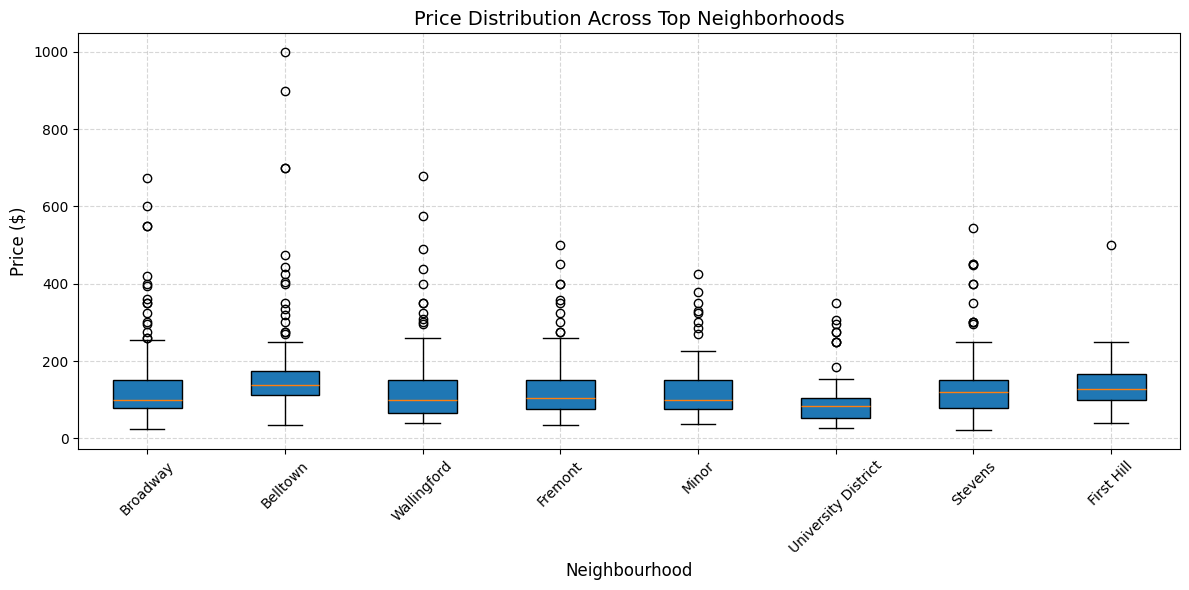

In [ ]:
# price distribution accross top neighbourhoods

top_neighbourhoods = (
    df_l["neighbourhood_cleansed"].value_counts().head(8).index
)

data_to_plot = [
    df_l[df_l["neighbourhood_cleansed"] == n]["price"] for n in top_neighbourhoods
]


plt.figure(figsize=(12, 6))
plt.boxplot(data_to_plot, labels=top_neighbourhoods, patch_artist=True)

plt.title("Price Distribution Across Top Neighborhoods", fontsize=14)
plt.xlabel("Neighbourhood", fontsize=12)
plt.ylabel("Price ($)", fontsize=12)
plt.xticks(rotation=45)
plt.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

In [22]:
# monthly price and occupancy trends

df_merged["is_booked"] = (df_merged["available"] == "f").astype(int)

monthly_trends = (
    df_merged.groupby("month")
    .agg(avg_price=("price", "mean"), occupancy_rate=("is_booked", "mean"))
    .reset_index()
)

fig, ax1 = plt.subplots(figsize=(12, 6))

color = "tab:blue"
ax1.set_xlabel("Month", fontsize=12)
ax1.set_ylabel("Average Price ($)", color=color, fontsize=12)
ax1.plot(
    monthly_trends["month"],
    monthly_trends["avg_price"],
    color=color,
    linewidth=2,
    marker="o",
    label="Avg Price",
)
ax1.tick_params(axis="y", labelcolor=color)

ax2 = ax1.twinx()
color = "tab:orange"
ax2.set_ylabel("Occupancy Rate", color=color, fontsize=12)
ax2.plot(
    monthly_trends["month"],
    monthly_trends["occupancy_rate"],
    color=color,
    linewidth=2,
    linestyle="--",
    marker="s",
    label="Occupancy Rate",
)
ax2.tick_params(axis="y", labelcolor=color)

plt.title("Monthly Price vs Occupancy Trends", fontsize=14, fontweight="bold")
plt.grid(True, linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

NameError: name 'df_merged' is not defined

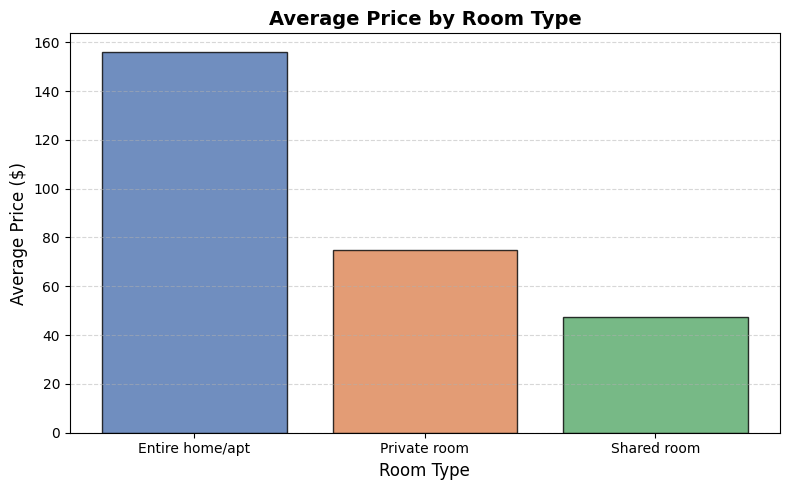

In [11]:
# average price by room type

room_price = df_l.groupby("room_type")["price"].mean().reset_index()

plt.figure(figsize=(8, 5))
plt.bar(
    room_price["room_type"],
    room_price["price"],
    color=["#4C72B0", "#DD8452", "#55A868"],
    edgecolor="black",
    alpha=0.8,
)

plt.title("Average Price by Room Type", fontsize=14, fontweight="bold")
plt.xlabel("Room Type", fontsize=12)
plt.ylabel("Average Price ($)", fontsize=12)
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

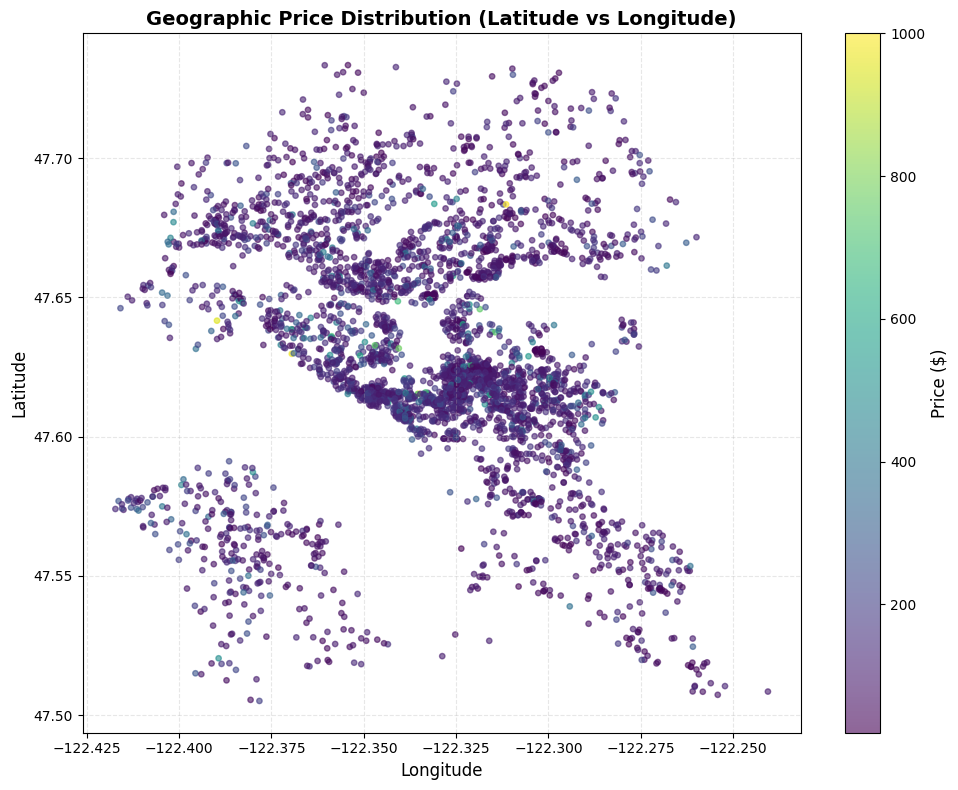

In [12]:
plt.figure(figsize=(10, 8))
sc = plt.scatter(
    df_l["longitude"],
    df_l["latitude"],
    c=df_l["price"],
    cmap="viridis",
    s=15,
    alpha=0.6,
)

cbar = plt.colorbar(sc)
cbar.set_label("Price ($)", fontsize=12)

plt.title(
    "Geographic Price Distribution (Latitude vs Longitude)",
    fontsize=14,
    fontweight="bold",
)
plt.xlabel("Longitude", fontsize=12)
plt.ylabel("Latitude", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:

cols = ['price', 'minimum_nights', 'availability_365', 'number_of_reviews']
corr = df_l[cols].corr()

plt.figure(figsize=(8, 6))
cax = plt.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)

plt.colorbar(cax)
plt.xticks(range(len(cols)), cols, rotation=45, ha='right')
plt.yticks(range(len(cols)), cols)

plt.title('Correlation Matrix of Airbnb Features', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

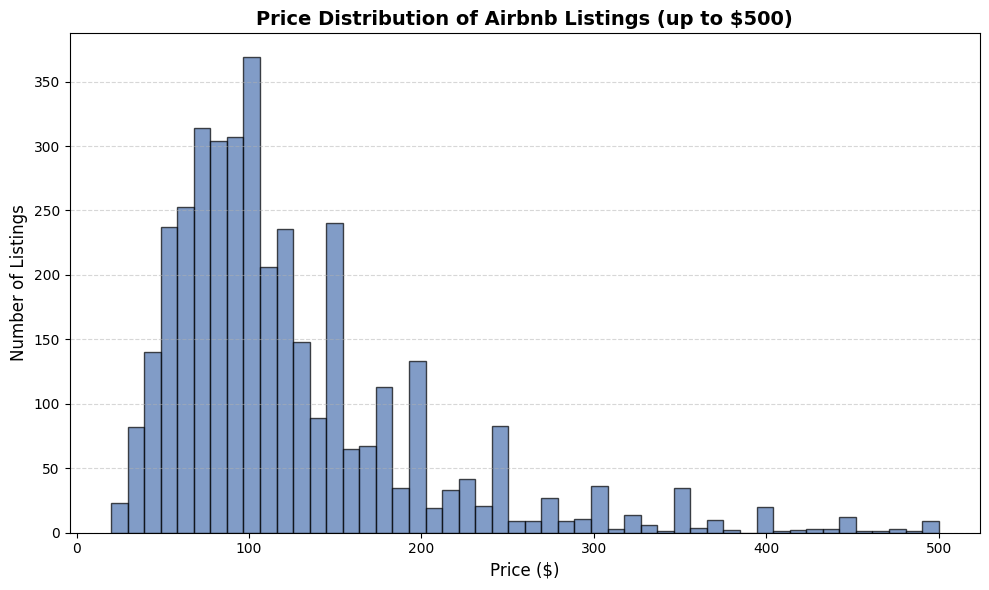

In [13]:
# price distribution

filtered_prices = df_l[df_l["price"] <= 500]["price"]

plt.figure(figsize=(10, 6))
plt.hist(
    filtered_prices, bins=50, color="#4C72B0", edgecolor="black", alpha=0.7
)

plt.title(
    "Price Distribution of Airbnb Listings (up to $500)",
    fontsize=14,
    fontweight="bold",
)
plt.xlabel("Price ($)", fontsize=12)
plt.ylabel("Number of Listings", fontsize=12)
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

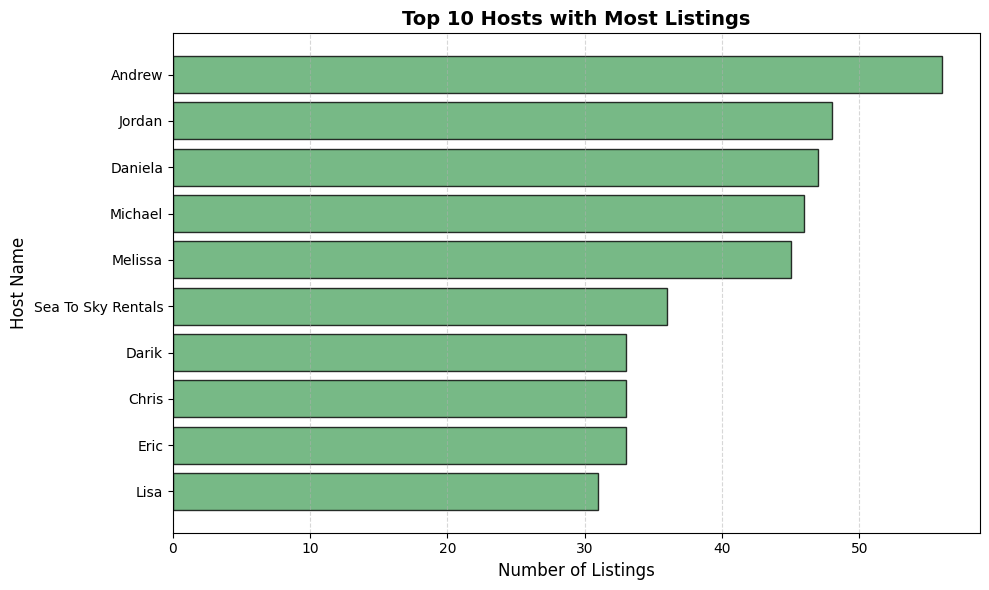

In [14]:
# top 10 hosts with most listings

top_hosts = df_l["host_name"].value_counts().head(10)

plt.figure(figsize=(10, 6))
plt.barh(
    top_hosts.index,
    top_hosts.values,
    color="#55A868",
    edgecolor="black",
    alpha=0.8,
)

plt.gca().invert_yaxis()
plt.title("Top 10 Hosts with Most Listings", fontsize=14, fontweight="bold")
plt.xlabel("Number of Listings", fontsize=12)
plt.ylabel("Host Name", fontsize=12)
plt.grid(axis="x", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

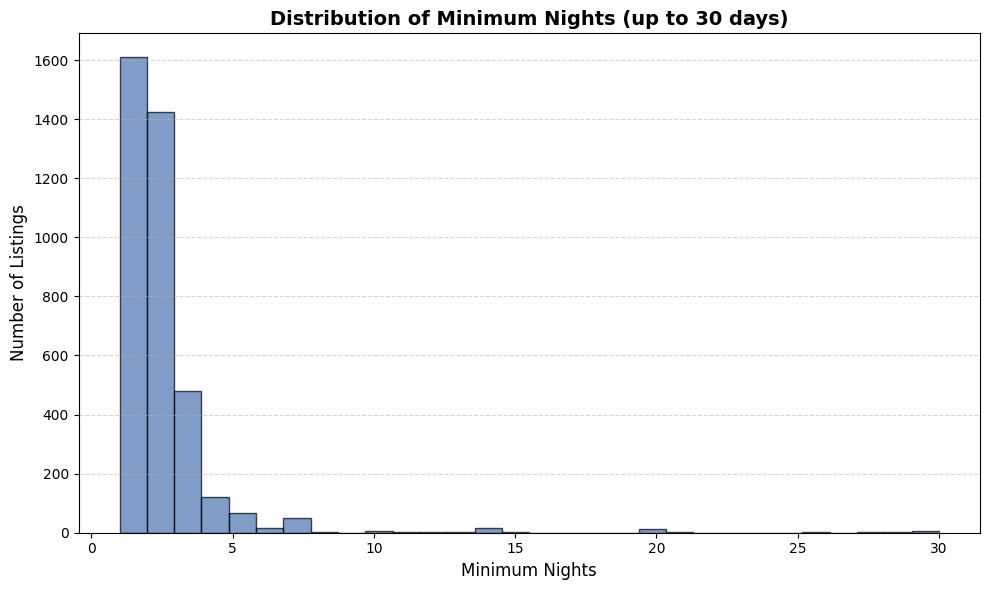

In [15]:
# minimum nights distribution

filtered_nights = df_l[df_l["minimum_nights"] <= 30]["minimum_nights"]

plt.figure(figsize=(10, 6))
plt.hist(
    filtered_nights, bins=30, color="#4C72B0", edgecolor="black", alpha=0.7
)

plt.title(
    "Distribution of Minimum Nights (up to 30 days)",
    fontsize=14,
    fontweight="bold",
)
plt.xlabel("Minimum Nights", fontsize=12)
plt.ylabel("Number of Listings", fontsize=12)
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

In [19]:
# weekend analysis

final_analysis_df["is_weekend"] = final_analysis_df["date"].dt.dayofweek >= 5

weekend_analysis = (
    final_analysis_df.groupby("is_weekend")[["price_x", "isbooked"]]
    .mean()
    .reset_index()
)

weekend_analysis["day_type"] = weekend_analysis["is_weekend"].map(
    {True: "Weekend", False: "Weekday"}
)

print(weekend_analysis[["day_type", "price_x", "isbooked"]])

  day_type     price_x  isbooked
0  Weekday  137.198889  0.329298
1  Weekend  139.817855  0.329620


         room_type   avg_price  listing_count
0  Entire home/apt  155.843369           2541
1     Private room   75.044828           1160
2      Shared room   47.547009            117


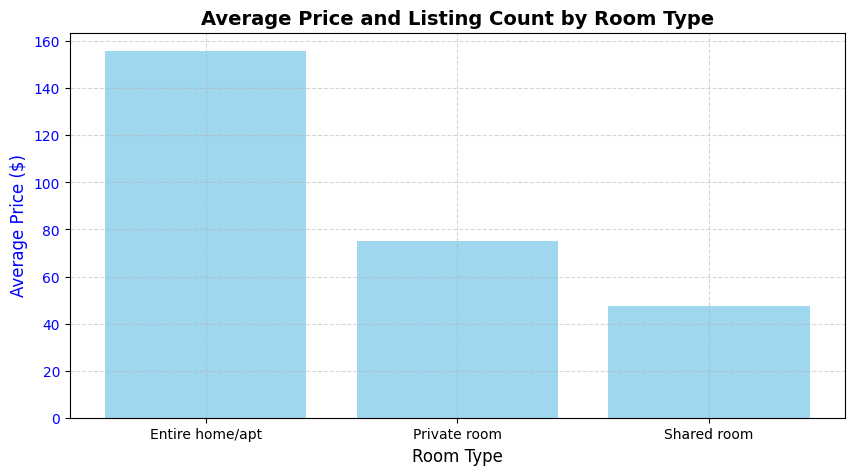

In [20]:
# roomtype analysis

room_stats = (
    df_l.groupby("room_type")
    .agg(avg_price=("price", "mean"), listing_count=("id", "count"))
    .reset_index()
)

print(room_stats)

fig, ax1 = plt.subplots(figsize=(10, 5))

ax1.bar(
    room_stats["room_type"],
    room_stats["avg_price"],
    color="skyblue",
    alpha=0.8,
)
ax1.set_xlabel("Room Type", fontsize=12)
ax1.set_ylabel("Average Price ($)", fontsize=12, color="blue")
ax1.tick_params(axis="y", labelcolor="blue")
plt.title(
    "Average Price and Listing Count by Room Type",
    fontsize=14,
    fontweight="bold",
)

plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

In [21]:
# revenue analysis

revenue_df = (
    final_analysis_df.groupby(["id", "neighbourhood_cleansed"])
    .agg(
        avg_price=("price_x", "mean"),
        total_booked_days=("isbooked", "sum"),
    )
    .reset_index()
)

revenue_df["estimated_revenue"] = (
    revenue_df["avg_price"] * revenue_df["total_booked_days"]
)

top_earners = revenue_df.sort_values(
    by="estimated_revenue", ascending=False
).head(5)

print("Top 5 Highest Earning Listings:")
print(
    top_earners[
        ["id", "neighbourhood_cleansed", "total_booked_days", "estimated_revenue"]
    ]
)

Top 5 Highest Earning Listings:
            id neighbourhood_cleansed  total_booked_days  estimated_revenue
977    3308979        West Queen Anne                145      188763.636364
1886   6066570                Stevens                329      179305.000000
3558   9497431               Belltown                230      173203.629630
3765  10136155            Lawton Park                320      153600.000000
2864   8036620            Portage Bay                289      152941.842105
